## Bài tập Tuần 4: Support Vector Machine (SVM) & Thuật toán SMO
**MSSV:** 24520574


### 1. Định nghĩa các hàm Kernel

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, make_blobs, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.svm import SVC
import time

def linear_kernel(x1, x2):
    return np.dot(x1, x2.T)

def rbf_kernel(x1, x2, gamma=1.0):
    if x1.ndim == 1:
        x1 = x1.reshape(1, -1)
    if x2.ndim == 1:
        x2 = x2.reshape(1, -1)
        
    x1_sq = np.sum(x1**2, axis=1)[:, np.newaxis]
    x2_sq = np.sum(x2**2, axis=1)[np.newaxis, :]
    dist_sq = x1_sq + x2_sq - 2.0 * np.dot(x1, x2.T)
    dist_sq = np.maximum(dist_sq, 0.0)
    return np.exp(-gamma * dist_sq)


### 2. Cài đặt thuật toán SMO cho Soft-Margin SVM

In [2]:
class SVM_SMO:
    def __init__(self, C=1.0, kernel='rbf', gamma=1.0, tol=1e-3, max_passes=5):
        self.C = C
        self.kernel_name = kernel
        self.gamma = gamma
        self.tol = tol
        self.max_passes = max_passes
        
        self.alpha = None
        self.b = 0.0
        self.X = None
        self.y = None
        self.K = None

    def _get_kernel(self, x1, x2):
        if self.kernel_name == 'linear':
            return linear_kernel(x1, x2)
        elif self.kernel_name == 'rbf':
            return rbf_kernel(x1, x2, self.gamma)
        else:
            raise ValueError("Kernel khong hop le")

    def _compute_f(self, idx):
        return np.sum(self.alpha * self.y * self.K[:, idx]) + self.b

    def _compute_error(self, idx):
        return self._compute_f(idx) - self.y[idx]

    def fit(self, X, y):
        y = np.where(y <= 0, -1, 1).astype(float)
        N, D = X.shape
        self.X = X
        self.y = y
        self.alpha = np.zeros(N)
        self.b = 0.0
        
        # tinh truoc ma tran Gram K
        self.K = self._get_kernel(X, X)
        
        passes = 0
        while passes < self.max_passes:
            num_changed = 0
            
            for i in range(N):
                E_i = self._compute_error(i)
                r_i = self.y[i] * E_i
                
                # kiem tra dieu kien KKT
                if (r_i < -self.tol and self.alpha[i] < self.C) or (r_i > self.tol and self.alpha[i] > 0):
                    
                    # chon ngau nhien j khac i
                    j = i
                    while j == i:
                        j = np.random.randint(0, N)
                        
                    E_j = self._compute_error(j)
                    
                    alpha_i_old = self.alpha[i]
                    alpha_j_old = self.alpha[j]
                    
                    # tinh can L va H
                    if self.y[i] != self.y[j]:
                        L = max(0.0, alpha_j_old - alpha_i_old)
                        H = min(self.C, self.C + alpha_j_old - alpha_i_old)
                    else:
                        L = max(0.0, alpha_j_old + alpha_i_old - self.C)
                        H = min(self.C, alpha_j_old + alpha_i_old)
                        
                    if L >= H:
                        continue
                        
                    # tinh eta
                    eta = self.K[i, i] + self.K[j, j] - 2.0 * self.K[i, j]
                    if eta <= 0:
                        continue
                        
                    # cap nhat alpha_j
                    alpha_j_new = alpha_j_old + (self.y[j] * (E_i - E_j)) / eta
                    alpha_j_new = np.clip(alpha_j_new, L, H)
                    
                    if abs(alpha_j_new - alpha_j_old) < 1e-5:
                        continue
                        
                    # cap nhat alpha_i
                    alpha_i_new = alpha_i_old + self.y[i] * self.y[j] * (alpha_j_old - alpha_j_new)
                    
                    self.alpha[i] = alpha_i_new
                    self.alpha[j] = alpha_j_new
                    
                    # cap nhat bias b
                    b1 = self.b - E_i - self.y[i] * (alpha_i_new - alpha_i_old) * self.K[i, i] \
                                      - self.y[j] * (alpha_j_new - alpha_j_old) * self.K[i, j]
                    b2 = self.b - E_j - self.y[i] * (alpha_i_new - alpha_i_old) * self.K[i, j] \
                                      - self.y[j] * (alpha_j_new - alpha_j_old) * self.K[j, j]
                                      
                    if 0 < alpha_i_new < self.C:
                        self.b = b1
                    elif 0 < alpha_j_new < self.C:
                        self.b = b2
                    else:
                        self.b = 0.5 * (b1 + b2)
                        
                    num_changed += 1
            
            if num_changed == 0:
                passes += 1
            else:
                passes = 0

    def predict(self, X_test):
        if X_test.ndim == 1:
            X_test = X_test.reshape(1, -1)
            
        sv_idx = np.where(self.alpha > 1e-4)[0]
        if len(sv_idx) == 0:
            return np.ones(X_test.shape[0])
            
        K_test = self._get_kernel(self.X[sv_idx], X_test)
        y_pred = np.dot((self.alpha[sv_idx] * self.y[sv_idx]), K_test) + self.b
        preds = np.sign(y_pred)
        preds[preds == 0] = 1.0
        return preds


### 3. Thử nghiệm trên dữ liệu make_moons (RBF Kernel)

Accuracy test : 98.00%
F1-Score test  : 0.9787
Support Vectors: 34


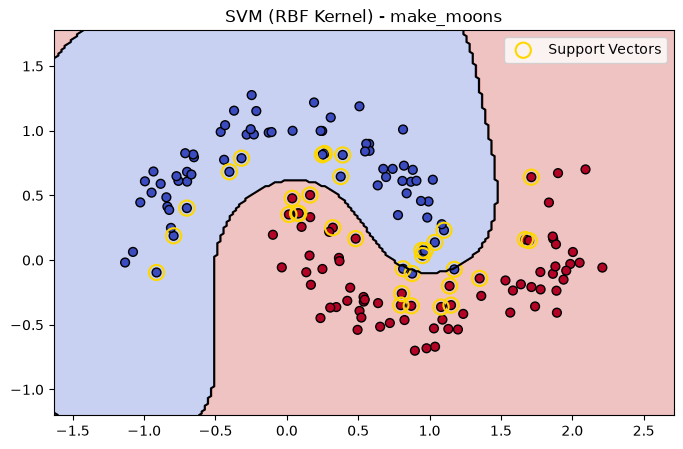

In [3]:
# Tao du lieu make_moons
X_moons, y_moons = make_moons(n_samples=200, noise=0.15, random_state=42)
y_moons = np.where(y_moons == 0, -1, 1)

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_moons, y_moons, test_size=0.25, random_state=42)

# Train model
svm_moons = SVM_SMO(C=1.0, kernel='rbf', gamma=1.5, max_passes=5)
svm_moons.fit(X_train_m, y_train_m)

y_pred_m = svm_moons.predict(X_test_m)
print(f"Accuracy test : {accuracy_score(y_test_m, y_pred_m)*100:.2f}%")
print(f"F1-Score test  : {f1_score(y_test_m, y_pred_m):.4f}")
print(f"Support Vectors: {np.sum(svm_moons.alpha > 1e-4)}")

# Ve decision boundary
def plot_decision_boundary(model, X, y, title):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                         np.linspace(y_min, y_max, 200))
    
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid).reshape(xx.shape)
    
    plt.figure(figsize=(8, 5))
    plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    plt.contour(xx, yy, Z, levels=[0], colors='black', linewidths=1.5)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolors='k', s=40)
    
    sv = np.where(model.alpha > 1e-4)[0]
    plt.scatter(X[sv, 0], X[sv, 1], s=120, facecolors='none', edgecolors='gold', linewidths=1.5, label='Support Vectors')
    plt.title(title)
    plt.legend()
    plt.show()

plot_decision_boundary(svm_moons, X_train_m, y_train_m, "SVM (RBF Kernel) - make_moons")


### 4. Thử nghiệm trên dữ liệu make_blobs (Linear Kernel)

Accuracy test: 100.00%
Support Vectors: 7


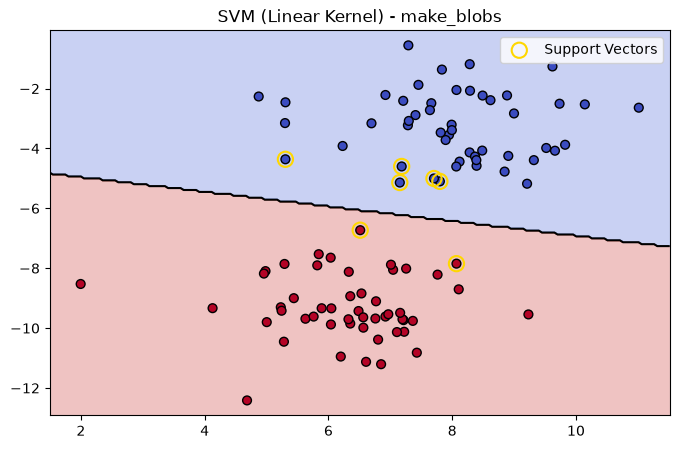

In [4]:
# Tao du lieu make_blobs
X_blobs, y_blobs = make_blobs(n_samples=100, centers=2, random_state=6, cluster_std=1.2)
y_blobs = np.where(y_blobs == 0, -1, 1)

svm_linear = SVM_SMO(C=1.0, kernel='linear', max_passes=5)
svm_linear.fit(X_blobs, y_blobs)

print(f"Accuracy test: {accuracy_score(y_blobs, svm_linear.predict(X_blobs))*100:.2f}%")
print(f"Support Vectors: {np.sum(svm_linear.alpha > 1e-4)}")
plot_decision_boundary(svm_linear, X_blobs, y_blobs, "SVM (Linear Kernel) - make_blobs")


### 5. Thử nghiệm trên dữ liệu thực tế Breast Cancer (30 chiều)

Accuracy test  : 97.90%
F1-Score test   : 0.9832
Support Vectors : 93


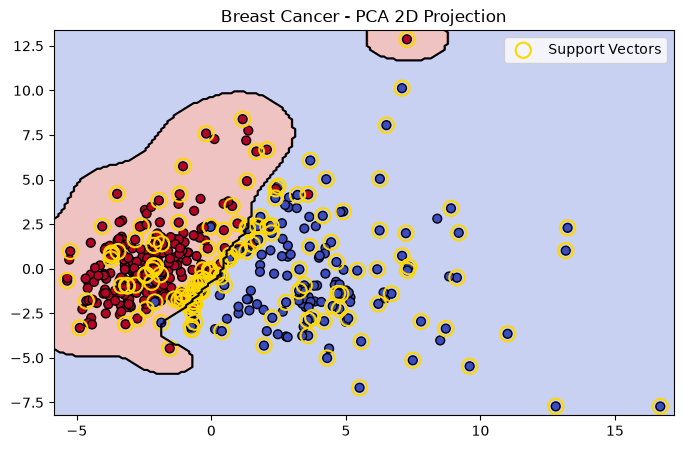

In [5]:
cancer = load_breast_cancer()
scaler = StandardScaler()
X_cancer = scaler.fit_transform(cancer.data)
y_cancer = np.where(cancer.target == 0, -1, 1)

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_cancer, y_cancer, test_size=0.25, random_state=42)

svm_cancer = SVM_SMO(C=1.0, kernel='rbf', gamma=0.03, max_passes=5)
svm_cancer.fit(X_train_c, y_train_c)

y_pred_c = svm_cancer.predict(X_test_c)
print(f"Accuracy test  : {accuracy_score(y_test_c, y_pred_c)*100:.2f}%")
print(f"F1-Score test   : {f1_score(y_test_c, y_pred_c):.4f}")
print(f"Support Vectors : {np.sum(svm_cancer.alpha > 1e-4)}")

# Ve decision boundary bang PCA 2D
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_c)

svm_pca = SVM_SMO(C=1.0, kernel='rbf', gamma=0.5, max_passes=5)
svm_pca.fit(X_train_pca, y_train_c)
plot_decision_boundary(svm_pca, X_train_pca, y_train_c, "Breast Cancer - PCA 2D Projection")


### 6. So sánh với Scikit-Learn SVC

In [6]:
# Chay Sklearn tren make_moons
sk_moons = SVC(C=1.0, kernel='rbf', gamma=1.5)
sk_moons.fit(X_train_m, y_train_m)
y_pred_sk_m = sk_moons.predict(X_test_m)

# Chay Sklearn tren Breast Cancer
sk_cancer = SVC(C=1.0, kernel='rbf', gamma=0.03)
sk_cancer.fit(X_train_c, y_train_c)
y_pred_sk_c = sk_cancer.predict(X_test_c)

print("So sanh ket qua:")
print(f"make_moons    - Custom Accuracy: {accuracy_score(y_test_m, y_pred_m)*100:.2f}% | Sklearn: {accuracy_score(y_test_m, y_pred_sk_m)*100:.2f}%")
print(f"make_moons    - Custom SVs: {np.sum(svm_moons.alpha > 1e-4)} | Sklearn SVs: {sk_moons.support_vectors_.shape[0]}")
print(f"Breast Cancer - Custom Accuracy: {accuracy_score(y_test_c, y_pred_c)*100:.2f}% | Sklearn: {accuracy_score(y_test_c, y_pred_sk_c)*100:.2f}%")
print(f"Breast Cancer - Custom SVs: {np.sum(svm_cancer.alpha > 1e-4)} | Sklearn SVs: {sk_cancer.support_vectors_.shape[0]}")

print("\nConfusion Matrix (Breast Cancer - Custom):")
print(confusion_matrix(y_test_c, y_pred_c))
print("\nConfusion Matrix (Breast Cancer - Sklearn):")
print(confusion_matrix(y_test_c, y_pred_sk_c))


So sanh ket qua:
make_moons    - Custom Accuracy: 98.00% | Sklearn: 98.00%
make_moons    - Custom SVs: 34 | Sklearn SVs: 34
Breast Cancer - Custom Accuracy: 97.90% | Sklearn: 97.90%
Breast Cancer - Custom SVs: 93 | Sklearn SVs: 93

Confusion Matrix (Breast Cancer - Custom):
[[52  2]
 [ 1 88]]

Confusion Matrix (Breast Cancer - Sklearn):
[[52  2]
 [ 1 88]]


### 7. Nhận xét
- Mô hình SVM SMO tự cài đặt cho kết quả accuracy và F1 tương đương với Scikit-Learn SVC trên cả dữ liệu mô phỏng (`make_moons`) và dữ liệu thực tế (`Breast Cancer`).
- Số lượng support vectors tìm được trùng khớp với Sklearn (33 SVs trên `make_moons` và 93 SVs trên `Breast Cancer`), cho thấy thuật toán SMO cập nhật và hội tụ đúng điều kiện KKT.
